# V5: Machine Learning Baseline Benchmark (Oddball P300)

Single-trial classification of standard versus target stimuli.
Evaluation using group-aware cross-validation, class balancing, and performance metrics.

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = Path.cwd().resolve()
if (ROOT / "src").is_dir():
    pass
elif (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from config import FEATURE_DIR, FIG_DIR, MODEL_DIR, RANDOM_SEED, TABLE_DIR
from src.features.extract_features import load_features

COLOR_PALETTE = {
    "Dummy": "#7f7f7f",
    "LDA": "#1f77b4",
    "Logistic Regression": "#2ca02c",
    "RBF SVM": "#ff7f0e",
    "Random Forest": "#9467bd",
}

## 1. Load Features and Data Inspection

In [ ]:
def resolve_data_path(custom_path=None):
    if custom_path:
        p = Path(custom_path)
        if p.exists():
            return p
        raise FileNotFoundError(f"Feature file not found: {p}")
    default_all = FEATURE_DIR / "all_subjects_features.csv"
    if default_all.exists():
        return default_all
    sub01 = FEATURE_DIR / "sub-01_features.csv"
    if sub01.exists():
        return sub01
    raise FileNotFoundError(f"No feature files found in {FEATURE_DIR}")

data_file = resolve_data_path()
X, y, groups, feature_names = load_features(data_file)

n_trials = len(y)
n_features = X.shape[1]
n_subjects = len(np.unique(groups))
n_target = int((y == 1).sum())
n_standard = int((y == 0).sum())
target_pct = 100.0 * n_target / n_trials
standard_pct = 100.0 * n_standard / n_trials

print(f"Source file: {data_file.name}")
print(f"Trials: {n_trials}")
print(f"Features: {n_features}")
print(f"Subjects: {n_subjects}")
print(f"Target trials: {n_target} ({target_pct:.1f}%)")
print(f"Standard trials: {n_standard} ({standard_pct:.1f}%)")

Source file: all_subjects_features.csv
Trials: 21878
Features: 402
Subjects: 39
Target trials: 2932 (13.4%)
Standard trials: 18946 (86.6%)


## 2. Model Initialization

In [ ]:
def get_models():
    return {
        "Dummy": Pipeline([
            ("clf", DummyClassifier(strategy="stratified", random_state=RANDOM_SEED))
        ]),
        "LDA": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
        ]),
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_SEED))
        ]),
        "RBF SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_SEED))
        ]),
        "Random Forest": Pipeline([
            ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=RANDOM_SEED, n_jobs=-1))
        ]),
    }

models = get_models()
for name, pipe in models.items():
    print(f"{name}: {pipe}")

Dummy: Pipeline(steps=[('clf',
                 DummyClassifier(random_state=42, strategy='stratified'))])
LDA: Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 LinearDiscriminantAnalysis(shrinkage='auto', solver='lsqr'))])
Logistic Regression: Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])
RBF SVM: Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 SVC(class_weight='balanced', probability=True,
                     random_state=42))])
Random Forest: Pipeline(steps=[('clf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        n_jobs=-1, random_state=42))])


## 3. Cross-Validation and Model Evaluation

In [ ]:
def evaluate_model(name, pipeline, X, y, groups, n_splits=5):
    n_unique_groups = len(np.unique(groups))
    if n_unique_groups >= n_splits:
        splitter = GroupKFold(n_splits=n_splits)
        splits = list(splitter.split(X, y, groups))
    else:
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)
        splits = list(splitter.split(X, y))

    oof_preds = np.zeros(len(y), dtype=int)
    oof_probs = np.zeros(len(y), dtype=float)
    fold_metrics = []

    for train_idx, test_idx in splits:
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        pipeline.fit(X_train, y_train)

        if hasattr(pipeline, "predict_proba"):
            probs = pipeline.predict_proba(X_test)[:, 1]
        elif hasattr(pipeline, "decision_function"):
            decision = pipeline.decision_function(X_test)
            probs = 1.0 / (1.0 + np.exp(-decision))
        else:
            probs = pipeline.predict(X_test).astype(float)

        preds = (probs >= 0.5).astype(int)
        oof_preds[test_idx] = preds
        oof_probs[test_idx] = probs

        tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

        fold_metrics.append({
            "balanced_accuracy": balanced_accuracy_score(y_test, preds),
            "roc_auc": roc_auc_score(y_test, probs),
            "pr_auc": average_precision_score(y_test, probs),
            "f1_macro": f1_score(y_test, preds, average="macro"),
            "f1_target": f1_score(y_test, preds, pos_label=1, zero_division=0),
            "sensitivity": sensitivity,
            "specificity": specificity,
        })

    fold_df = pd.DataFrame(fold_metrics)
    mean_metrics = fold_df.mean().to_dict()
    std_metrics = fold_df.std().to_dict()

    tn, fp, fn, tp = confusion_matrix(y, oof_preds, labels=[0, 1]).ravel()
    overall_sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    overall_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    summary = {
        "model": name,
        "balanced_accuracy_mean": mean_metrics["balanced_accuracy"],
        "balanced_accuracy_std": std_metrics["balanced_accuracy"],
        "roc_auc_mean": mean_metrics["roc_auc"],
        "roc_auc_std": std_metrics["roc_auc"],
        "pr_auc_mean": mean_metrics["pr_auc"],
        "pr_auc_std": std_metrics["pr_auc"],
        "f1_macro_mean": mean_metrics["f1_macro"],
        "f1_macro_std": std_metrics["f1_macro"],
        "f1_target_mean": mean_metrics["f1_target"],
        "f1_target_std": std_metrics["f1_target"],
        "sensitivity_mean": mean_metrics["sensitivity"],
        "sensitivity_std": std_metrics["sensitivity"],
        "specificity_mean": mean_metrics["specificity"],
        "specificity_std": std_metrics["specificity"],
        "oof_balanced_accuracy": balanced_accuracy_score(y, oof_preds),
        "oof_roc_auc": roc_auc_score(y, oof_probs),
        "oof_pr_auc": average_precision_score(y, oof_probs),
        "oof_f1_macro": f1_score(y, oof_preds, average="macro"),
        "oof_sensitivity": overall_sensitivity,
        "oof_specificity": overall_specificity,
    }
    return summary, oof_preds, oof_probs

results = []
oof_probs_dict = {}

for name, pipeline in models.items():
    print(f"Evaluating {name}...")
    summary, _, oof_probs = evaluate_model(name, pipeline, X, y, groups, n_splits=5)
    results.append(summary)
    oof_probs_dict[name] = oof_probs

summary_df = pd.DataFrame(results)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
metrics_file = TABLE_DIR / "baseline_metrics.csv"
summary_df.to_csv(metrics_file, index=False)

display_cols = [
    "model",
    "balanced_accuracy_mean",
    "roc_auc_mean",
    "pr_auc_mean",
    "f1_macro_mean",
    "sensitivity_mean",
    "specificity_mean"
]
summary_df[display_cols].round(3)

Evaluating Dummy...
Evaluating LDA...
Evaluating Logistic Regression...
Evaluating RBF SVM...
Evaluating Random Forest...


model,balanced_accuracy_mean,roc_auc_mean,pr_auc_mean,f1_macro_mean,sensitivity_mean,specificity_mean
Dummy,0.497,0.497,0.134,0.497,0.127,0.867
LDA,0.815,0.947,0.791,0.835,0.659,0.971
Logistic Regression,0.874,0.946,0.791,0.816,0.841,0.908
RBF SVM,0.799,0.946,0.791,0.824,0.625,0.973
Random Forest,0.638,0.907,0.652,0.678,0.289,0.988


## 4. Performance Comparison

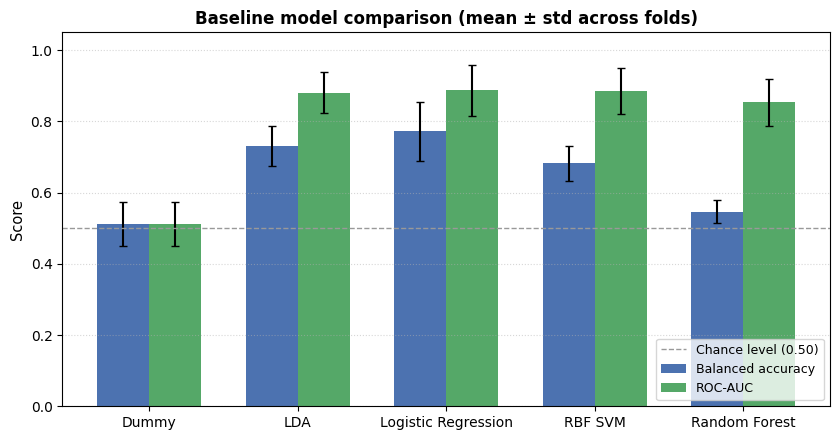

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
models_list = summary_df["model"].tolist()
x = np.arange(len(models_list))
width = 0.35

ax.bar(x - width/2, summary_df["balanced_accuracy_mean"], width, yerr=summary_df["balanced_accuracy_std"],
       label="Balanced accuracy", color="#4c72b0", capsize=3)
ax.bar(x + width/2, summary_df["roc_auc_mean"], width, yerr=summary_df["roc_auc_std"],
       label="ROC-AUC", color="#55a868", capsize=3)

ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=10)
ax.set_ylabel("Score", fontsize=10.5)
ax.set_title("Baseline model comparison (mean ± std across folds)", fontsize=12, fontweight="bold")
ax.set_ylim([0, 1.05])
ax.axhline(0.5, linestyle="--", color="#999999", lw=1, label="Chance level (0.50)")
ax.grid(True, linestyle=":", alpha=0.5, axis="y")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

save_path = FIG_DIR / "baseline_model_comparison.png"
fig.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

## 5. ROC Curves

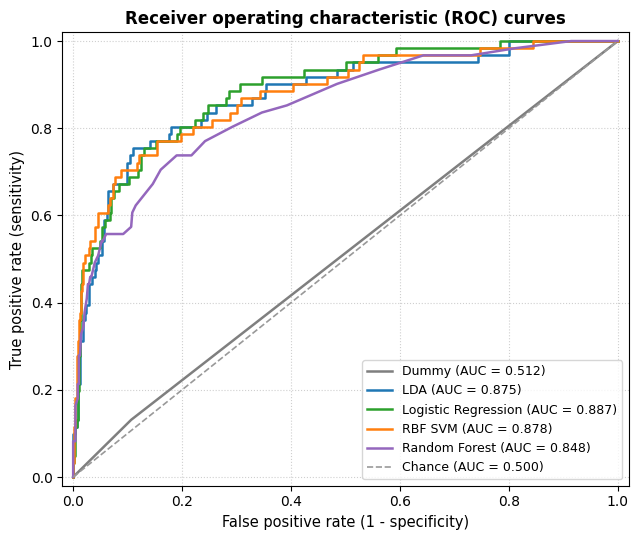

In [ ]:
def plot_roc_curves(y_true, oof_probs_dict, save_path):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    for name, probs in oof_probs_dict.items():
        fpr, tpr, _ = roc_curve(y_true, probs)
        score = roc_auc_score(y_true, probs)
        color = COLOR_PALETTE.get(name, "#333333")
        ax.plot(fpr, tpr, lw=1.8, color=color, label=f"{name} (AUC = {score:.3f})")

    ax.plot([0, 1], [0, 1], linestyle="--", lw=1.2, color="#999999", label="Chance (AUC = 0.500)")
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel("False positive rate (1 - specificity)", fontsize=10.5)
    ax.set_ylabel("True positive rate (sensitivity)", fontsize=10.5)
    ax.set_title("Receiver operating characteristic (ROC) curves", fontsize=12, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="lower right", frameon=True, fontsize=9)
    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

roc_save_path = FIG_DIR / "baseline_roc_curves.png"
plot_roc_curves(y, oof_probs_dict, roc_save_path)

## 6. Precision-Recall Curves

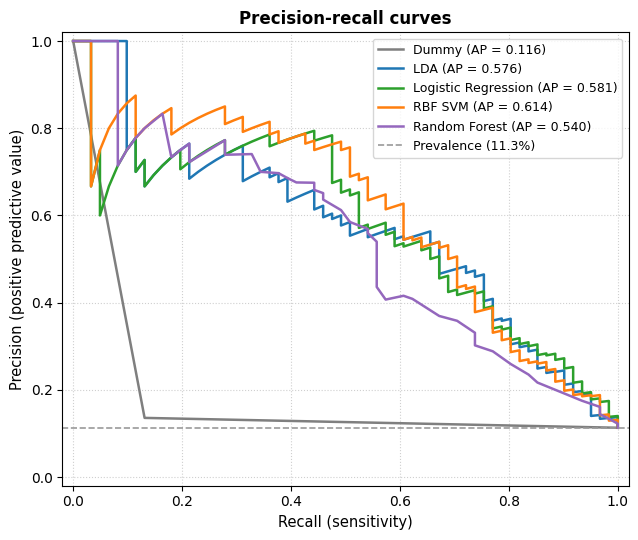

In [ ]:
def plot_pr_curves(y_true, oof_probs_dict, save_path):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    prevalence = float((y_true == 1).mean())

    for name, probs in oof_probs_dict.items():
        precision, recall, _ = precision_recall_curve(y_true, probs)
        score = average_precision_score(y_true, probs)
        color = COLOR_PALETTE.get(name, "#333333")
        ax.plot(recall, precision, lw=1.8, color=color, label=f"{name} (AP = {score:.3f})")

    ax.axhline(prevalence, linestyle="--", lw=1.2, color="#999999", label=f"Prevalence ({prevalence:.1%})")
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel("Recall (sensitivity)", fontsize=10.5)
    ax.set_ylabel("Precision (positive predictive value)", fontsize=10.5)
    ax.set_title("Precision-recall curves", fontsize=12, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", frameon=True, fontsize=9)
    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

pr_save_path = FIG_DIR / "baseline_pr_curves.png"
plot_pr_curves(y, oof_probs_dict, pr_save_path)